<a href="https://colab.research.google.com/github/zhiyuguo-innis/MSSP607/blob/main/WeeklyModules/Week07/PARTICIPATION%20ACTIVITY%20Week%207%3A%20Export%20a%20bar%20chart%20from%20a%20data%20frame%20to%20a%20PDF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Participation Activity Week 7: Export a Bar Chart from a Data Frame to a PDF
**MSSP 607** · Zhiyu Guo

**Tasks**
1. Create a bar chart of yearly sales from the Internet Sales data set.
2. Save the active figure to a PDF file.

## 1. Import libraries

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

## 2. Load the Internet Sales data
In Colab, if `InternetSales.csv` is not already in the session's file panel, the cell below opens an upload dialog.

In [2]:
csv_file = "InternetSales.csv"

if not os.path.exists(csv_file):
    from google.colab import files   # only runs inside Colab
    files.upload()

sales = pd.read_csv(csv_file, low_memory=False)
print(sales.shape)
sales[["SalesOrderNumber", "EnglishProductName", "OrderDate", "SalesAmount"]].head()

Saving InternetSales.csv to InternetSales.csv
(60398, 60)


,SalesOrderNumber,EnglishProductName,OrderDate,SalesAmount
0,SO43793,"Mountain-100 Silver, 38",1/19/2011,3399.99
1,SO51522,"Mountain-200 Silver, 38",1/18/2013,2319.99
2,SO51522,Fender Set - Mountain,1/18/2013,21.98
3,SO57418,"Touring-1000 Blue, 46",5/3/2013,2384.07
4,SO57418,Touring Tire,5/3/2013,28.99


## 3. Check the two columns the chart needs

In [3]:
sales[["OrderDate", "SalesAmount"]].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60398 entries, 0 to 60397
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   OrderDate    60398 non-null  object 
 1   SalesAmount  60398 non-null  float64
dtypes: float64(1), object(1)
memory usage: 943.8+ KB


`OrderDate` is read in as text, so convert it to a datetime and pull out the year.
`SalesAmount` is already numeric (it equals `ExtendedAmount` minus `DiscountAmount`).

In [4]:
sales["OrderDate"] = pd.to_datetime(sales["OrderDate"], format="%m/%d/%Y")
sales["OrderYear"] = sales["OrderDate"].dt.year

print("First order:", sales["OrderDate"].min().date())
print("Last order: ", sales["OrderDate"].max().date())

First order: 2010-12-29
Last order:  2014-01-28


## 4. Total sales by year

In [5]:
yearly_sales = sales.groupby("OrderYear")["SalesAmount"].sum()
yearly_sales.round(2)

,SalesAmount
OrderYear,
2010,43421.04
2011,7075525.93
2012,5842485.20
2013,16351550.34
2014,45694.72


**Note:** 2010 and 2014 are partial years. The data starts on 29 Dec 2010 and ends on 28 Jan 2014, so those two bars cover only a few days or weeks. They are not comparable to the full years 2011–2013.

In [6]:
orders_per_year = sales.groupby("OrderYear")["OrderDate"].agg(["min", "max", "count"])
orders_per_year

,min,max,count
OrderYear,,,
2010,2010-12-29,2010-12-31,14
2011,2011-01-01,2011-12-31,2216
2012,2012-01-01,2012-12-31,3397
2013,2013-01-01,2013-12-31,52801
2014,2014-01-01,2014-01-28,1970


## 5. Bar chart of yearly sales, saved to PDF
`plt.savefig()` saves the current (active) figure. It has to run **in the same cell** that draws the chart and **before** `plt.show()`. In Jupyter/Colab the figure is closed when the cell finishes, so a `savefig` call in a later cell writes a blank page.

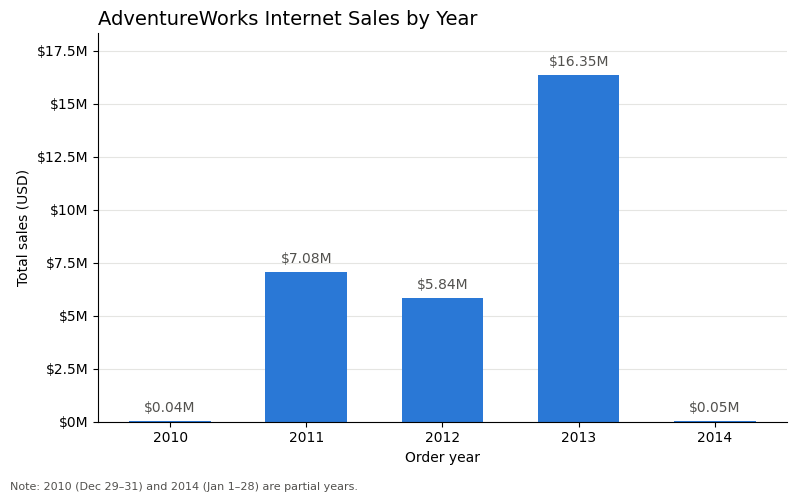

Saved: yearly_sales_bar_chart.pdf (17,186 bytes)


In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(yearly_sales.index.astype(str), yearly_sales.values,
              color="#2a78d6", width=0.6)

# Label each bar with its total in millions of dollars
ax.bar_label(bars, labels=[f"${v/1e6:,.2f}M" for v in yearly_sales.values],
             padding=4, fontsize=10, color="#52514e")

ax.set_title("AdventureWorks Internet Sales by Year", fontsize=14, loc="left")
ax.set_xlabel("Order year")
ax.set_ylabel("Total sales (USD)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v/1e6:g}M"))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e2", linewidth=0.8)
ax.set_axisbelow(True)
ax.margins(y=0.12)

fig.text(0.01, 0.01, "Note: 2010 (Dec 29–31) and 2014 (Jan 1–28) are partial years.",
         fontsize=8, color="#52514e")
fig.tight_layout(rect=(0, 0.03, 1, 1))

# Save the active figure to PDF, then display it
pdf_file = "yearly_sales_bar_chart.pdf"
plt.savefig(pdf_file, format="pdf", bbox_inches="tight")
plt.show()

print(f"Saved: {pdf_file} ({os.path.getsize(pdf_file):,} bytes)")

Download the PDF from Colab (skipped automatically outside Colab):

In [8]:
try:
    from google.colab import files
    files.download(pdf_file)
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>